# B 24시간 · 주말 비교 · 반복 취약 도로 (Q1 · Q2 · Q3)

담당: B · 노션 분석 설계 **6.2 · 6.3 · 10.2**

| 질문 | 이 노트북에서 보는 것 | 판정 기준 (결과를 보기 전에 정함) |
|---|---|---|
| Q1 얼마나 느려지나 | 강도별 · 도로 유형별 평소 대비 통행시간 비율 | 기술통계 (사건 · 시간 수를 함께 적는다) |
| Q3 언제 피해가 큰가 | 24시간 · 평일 / 주말, 출퇴근 · 낮 · 밤 | 출퇴근 − 나머지 비율 차이의 95% 신뢰구간(학습)이 0을 포함하지 않고, 학습 · 평가 시즌 방향이 같으면 "출퇴근에 피해가 몰린다" (6.3 (4)). 평가를 열기 전 결과는 '(평가 확인 전)'으로 적는다 |
| Q2 어디서 반복되나 | 반복 취약 도로 목록 → C (지도 · 열선 · 제설 우선 구간) | 사건 절반 이상에서 상위 20%, 최소 비율은 Dev로 (10.2) |

**입력**
- `data/derived/topis_weather/road_hourly_24h_train_dev_v01.parquet`: 24시간 도로 표. `python src/analysis/hourly_24h.py`로 C 링크 기본표 v02에서 만든다 (평일 · 토 · 일 따로 평소값, 공휴일 제외)
- `data/shared/train_dev/vulnerable_roads_train_dev.csv`: 반복 취약 도로. `python src/analysis/vulnerable_roads.py`로 만든다
- 두 표는 처음 셀의 `RUN_BUILD = True`일 때만 다시 만든다 (기본 `False`는 읽기만)

**Test 시즌**: 분석 설계 1.1 · 7.3에 따라 이 노트북은 Train + Dev(학습 3년)만 본다. 6.3 (4)의 '평가 시즌 방향 확인'과 10.2 (3) 반복성 확인은 마지막 평가 때 `OPEN_TEST = True`로 한 번만 연다.

In [1]:
import sys, subprocess
from pathlib import Path
def find_project_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'README.md').is_file() and (candidate / '.git').exists():
            return candidate
    raise FileNotFoundError('프로젝트 루트를 찾지 못했습니다.')

ROOT = find_project_root()
RUN_BUILD = False   # True: 24시간 표 · 반복 취약 도로 표를 다시 만든다 (약 3분)
OPEN_TEST = False   # True: 마지막 평가 때만. Test 시즌 방향 확인 · 반복성 검정
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.io_utils import add_model_set, load_processed
from src.analysis import hourly_24h as H, vulnerable_roads as V

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
FIG = ROOT / 'outputs' / 'figures' / 'ljh'; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / 'outputs' / 'tables'
pd.set_option('display.width', 160)

## 1. 24시간 표 읽기

In [2]:
if RUN_BUILD:
    subprocess.run([sys.executable, str(ROOT / 'src/analysis/hourly_24h.py')], check=True)

parts = [pd.read_parquet(H.out_path('train_dev'))] + ([pd.read_parquet(H.out_path('holdout'))] if OPEN_TEST else [])
h = add_model_set(pd.concat(parts, ignore_index=True), include_test=OPEN_TEST)
w = load_processed('weather_hourly', include_test=OPEN_TEST)[['date', 'hour', 'precip_mm', 'new_snow_3h_cm', 'temp_c']]
w['date'] = pd.to_datetime(w['date'])
h = h.merge(w, on=['date', 'hour'], how='left')

BANDS = {'출퇴근': [8, 9, 18, 19, 20], '낮': list(range(11, 17)), '밤': [23, 0, 1, 2, 3, 4, 5]}
band_of = {hr: b for b, hrs in BANDS.items() for hr in hrs}
h['band'] = h['hour'].map(band_of).fillna('기타')
h['day2'] = np.where(h['daytype'].eq('평일'), '평일', '주말')
h['group'] = h['impact'].fillna(h['weather_group'])        # 맑음 · 약한 비·눈 · 강한 비 · 호우 · 보통 눈 · 많은 눈
h['kind'] = h['group'].map({'강한 비': '비', '호우': '비', '보통 눈': '눈', '많은 눈': '눈'})
# 악천후 시간을 '내리는 중'(사건 시작~끝 시각)과 '그친 뒤'(영향 시간: 눈 12시간 · 비 3시간)로 나눈다
ev_se = load_processed('weather_events', include_test=OPEN_TEST)[['event_id', 'start', 'end', 'model_set']]
# 사건 번호는 train_dev · holdout 파일마다 0부터라 겹친다 → 세트까지 붙여서 맞춘다
ev_se = ev_se.rename(columns={'model_set': 'ev_set'})
ev_se['ev_set'] = ev_se['ev_set'].replace({'train': 'learn', 'dev': 'learn'})
h['ev_set'] = h['model_set'].replace({'train': 'learn', 'dev': 'learn'})
ev_se['end'] = pd.to_datetime(ev_se['end'])
h = h.merge(ev_se[['event_id', 'ev_set', 'end']].rename(columns={'end': 'event_end'}), on=['event_id', 'ev_set'], how='left')
h['event_id'] = np.where(h['event_id'].notna(), h['ev_set'] + '_' + h['event_id'].astype('Int64').astype(str), None)
h['phase'] = np.where(h['kind'].isna(), None,
                      np.where(pd.to_datetime(h['datetime']) <= h['event_end'], '내리는 중', '그친 뒤'))
print(f"{len(h):,}행 · 도로 · 방향 {h[['road_id','direction']].drop_duplicates().shape[0]}개 · "
      f"{h['date'].min():%Y-%m-%d} ~ {h['date'].max():%Y-%m-%d} · 비율 빈값 {h['ratio'].isna().mean():.2%}")
h.groupby(['model_set', 'season']).size().rename('행').to_frame()

2,989,440행 · 도로 · 방향 180개 · 2022-11-27 ~ 2025-09-23 · 비율 빈값 0.63%


행
model_set season                
dev       2024-25_winter  414720
          2025_summer     583200
train     2022-23_winter  419040
          2023-24_winter  423360
          2023_summer     578880
          2024_summer     570240

시간마다 **서울 비율** = 그 시간 180개 도로 · 방향 비율의 평균. 시간대 비교는 이 값을 한 시간 = 한 표본으로 쓴다
(도로끼리는 같은 날씨를 같이 겪어 서로 독립이 아니므로, 도로 행을 그대로 세면 표본이 부풀려진다).
시간 수 표는 아래 모든 결과의 표본 크기다.

In [3]:
KEYS = ['model_set', 'season', 'date', 'hour', 'daytype', 'day2', 'band', 'group', 'kind', 'phase', 'event_id']
city = (h.groupby(KEYS, dropna=False)
          .agg(ratio=('ratio', 'mean'), congested=('is_congested', 'mean'), precip=('precip_mm', 'first'),
               snow3h=('new_snow_3h_cm', 'first')).reset_index()
          .dropna(subset=['ratio']))   # 도로가 전부 빈 시간(TOPIS 수집 공백)은 뺀다
ORDER = ['맑음', '약한 비·눈', '강한 비', '호우', '보통 눈', '많은 눈']
hours_n = city.pivot_table(index='group', columns=['day2', 'band'], values='ratio', aggfunc='size').reindex(ORDER)
hours_n

band,기타,낮,밤,출퇴근,기타,낮,밤,출퇴근
group,,,,,,,,
맑음,981,1012,1119,812,2405,2395,2806,2026
약한 비·눈,67,65,72,57,173,169,226,121
강한 비,78,59,111,66,173,174,183,142
호우,20,18,27,17,82,90,89,72
보통 눈,31,28,35,27,86,91,99,74
많은 눈,19,18,18,20,29,33,38,25


## 2. Q1 얼마나 느려지나 (평일 출퇴근)

In [4]:
wd = h[h['daytype'].eq('평일') & h['band'].eq('출퇴근')]
q1 = (wd.groupby(['group', 'function_type'])['ratio'].agg(['median', 'mean', lambda s: s.quantile(.9)])
        .rename(columns={'<lambda_0>': 'p90'}).unstack('function_type').reindex(ORDER).round(3))
q1['사건 수'] = wd.groupby('group')['event_id'].nunique().reindex(ORDER)
q1.to_csv(TAB / 'ljh_comparison_q1_intensity.csv', encoding='utf-8-sig')
q1

median          mean           p90        사건 수
function_type 도시고속도로  주간선도로 도시고속도로  주간선도로 도시고속도로  주간선도로     
group                                                       
맑음             1.000  1.000  1.028  1.013  1.246  1.117    0
약한 비·눈         1.049  1.026  1.106  1.048  1.387  1.176   67
강한 비           1.049  1.034  1.116  1.065  1.466  1.230   29
호우             1.013  1.021  1.046  1.043  1.303  1.174    7
보통 눈           0.993  0.990  0.993  0.995  1.299  1.155   19
많은 눈           1.002  0.991  0.989  0.986  1.295  1.135    2

In [5]:
# 시간당 강수 · 3시간 신적설 구간별 (평일 출퇴근, 서울 비율)
c_wd = city[city['day2'].eq('평일') & city['band'].eq('출퇴근')]
rain_bin = pd.cut(c_wd['precip'], [-0.1, 0, 1, 5, 10, 30, 200], labels=['0', '~1', '1~5', '5~10', '10~30', '30+'])
snow_bin = pd.cut(c_wd['snow3h'], [-0.1, 0, 1, 3, 5, 50], labels=['0', '~1', '1~3', '3~5', '5+'])
summer = c_wd['season'].str.contains('summer')
q1b = pd.concat({
    '비 (여름)': c_wd[summer].groupby(rain_bin[summer], observed=True)['ratio'].agg(['median', 'size']),
    '신적설 (겨울)': c_wd[~summer].groupby(snow_bin[~summer], observed=True)['ratio'].agg(['median', 'size'])})
q1b.round(3)

median  size
비 (여름)   0       1.007  1263
         ~1      1.052    82
         1~5     1.092    45
         5~10    1.097    17
         10~30   1.121     7
         30+     1.132     1
신적설 (겨울) 0       1.008  1027
         ~1      1.037    12
         1~3     1.091     5
         3~5     1.634     1

## 3. Q3 언제 피해가 큰가: 24시간 그림

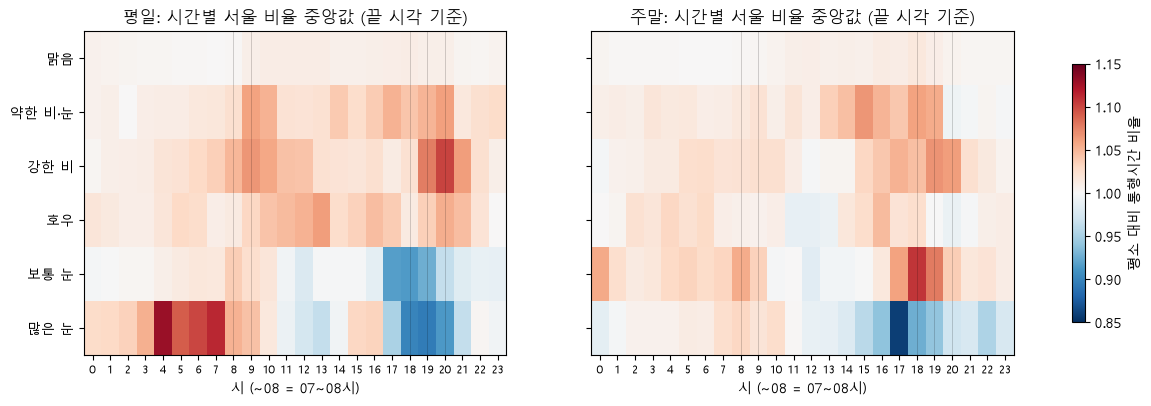

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, d2 in zip(axes, ['평일', '주말']):
    t = city[city['day2'].eq(d2)].pivot_table(index='group', columns='hour', values='ratio', aggfunc='median').reindex(ORDER)
    im = ax.imshow(t.values, aspect='auto', cmap='RdBu_r', vmin=0.85, vmax=1.15)
    ax.set_xticks(range(24)); ax.set_xticklabels(t.columns, fontsize=8)
    ax.set_yticks(range(len(ORDER))); ax.set_yticklabels(ORDER)
    for hr in BANDS['출퇴근']:
        ax.axvline(list(t.columns).index(hr), color='k', lw=0.4, alpha=.3)
    ax.set_title(f'{d2}: 시간별 서울 비율 중앙값 (끝 시각 기준)'); ax.set_xlabel('시 (~08 = 07~08시)')
fig.colorbar(im, ax=axes, shrink=.8, label='평소 대비 통행시간 비율')
fig.savefig(FIG / 'comparison_24h_heatmap.png', dpi=150, bbox_inches='tight')

In [7]:
band_tab = city.pivot_table(index='group', columns=['day2', 'band'], values='ratio', aggfunc='median').reindex(ORDER)
band_tab = band_tab[[(d, b) for d in ['평일', '주말'] for b in ['출퇴근', '낮', '밤', '기타']]]
band_tab.to_csv(TAB / 'ljh_comparison_band_median.csv', encoding='utf-8-sig')
band_tab.round(3)

day2       평일                          주말                     
band      출퇴근      낮      밤     기타    출퇴근      낮      밤     기타
group                                                         
맑음      1.007  1.010  1.004  1.003  1.003  1.009  1.002  1.002
약한 비·눈  1.041  1.026  1.009  1.019  1.020  1.039  1.012  1.009
강한 비    1.064  1.028  1.012  1.036  1.039  1.017  1.011  1.024
호우      1.024  1.041  1.014  1.028  1.004  1.017  1.017  1.012
보통 눈    1.011  0.991  1.004  1.013  1.047  1.000  1.024  1.021
많은 눈    0.997  1.011  1.032  1.018  0.998  0.977  1.004  1.010

## 4. Q3 판정: 출퇴근에 피해가 몰리나

같은 강도 안에서 `출퇴근 중앙값 − 낮(또는 밤) 중앙값`을 구하고, **사건 단위로 묶어** 부트스트랩한다 (2,000번).
한 사건의 시간들은 서로 닮아서, 시간을 하나씩 뽑으면 신뢰구간이 실제보다 좁아진다. 맑음은 날짜 단위로 묶는다.

In [8]:
rng = np.random.default_rng(20261127)
N_BOOT = 2000

def diff_ci(t, a='출퇴근', b='낮', col='band'):
    # col 열이 a 인 시간의 중앙값 − b 인 시간의 중앙값, 사건(맑음은 날짜) 단위로 묶어 부트스트랩
    t = t[t[col].isin([a, b])].copy()
    t['cl'] = np.where(t['event_id'].isna(), 'd' + t['date'].astype(str), t['event_id'].astype(str))
    point = t.loc[t[col].eq(a), 'ratio'].median() - t.loc[t[col].eq(b), 'ratio'].median()
    groups = {k: g[[col, 'ratio']].to_numpy() for k, g in t.groupby('cl')}
    keys = list(groups); boots = []
    for _ in range(N_BOOT):
        s = np.concatenate([groups[k] for k in rng.choice(keys, len(keys))])
        ra, rb = s[s[:, 0] == a, 1].astype(float), s[s[:, 0] == b, 1].astype(float)
        if len(ra) and len(rb):
            boots.append(np.median(ra) - np.median(rb))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return point, lo, hi, len(keys)

def compare(base, a, b, col='band'):
    # 한 줄: 학습(Train + Dev) 차이 · 95% 구간 · 묶음 수, 보조로 Train / Dev 따로, OPEN_TEST 면 평가(Test) 차이
    learn = base[base['model_set'].ne('test')]
    p, lo, hi, n = diff_ci(learn, a, b, col)
    diff = lambda x: x.loc[x[col].eq(a), 'ratio'].median() - x.loc[x[col].eq(b), 'ratio'].median()
    out = {'학습 차이': p, '95% 하한': lo, '95% 상한': hi, '묶음 수': n,
           'Train 차이': diff(learn[learn['model_set'].eq('train')]), 'Dev 차이': diff(learn[learn['model_set'].eq('dev')])}
    if OPEN_TEST:
        out['평가 차이'] = diff(base[base['model_set'].eq('test')])
    return out

def judge(t, pos='출퇴근에 몰림', neg='출퇴근이 덜함'):
    # 노션 분석 설계 6.3 (4): 학습 구간이 0 밖 + 학습 · 평가 시즌 방향이 같으면 판정. 평가를 열기 전에는 '평가 확인 전'
    t['학습 구간 0 밖'] = (t['95% 하한'] > 0) | (t['95% 상한'] < 0)
    t['보조: Train·Dev 같은 방향'] = np.sign(t['Train 차이']) == np.sign(t['Dev 차이'])
    word = np.where(t['학습 차이'] > 0, pos, neg)
    if OPEN_TEST:
        same = np.sign(t['평가 차이']) == np.sign(t['학습 차이'])
        t['판정'] = np.where(~t['학습 구간 0 밖'], '판정 보류', np.where(same, word, '평가에서 방향 다름'))
    else:
        t['판정'] = np.where(t['학습 구간 0 밖'], pd.Series(word) + ' (평가 확인 전)', '판정 보류')
    return t

GROUPS = {'맑음': ['맑음'], '비 전체': ['강한 비', '호우'], '강한 비': ['강한 비'], '호우': ['호우'],
          '눈 전체': ['보통 눈', '많은 눈'], '보통 눈': ['보통 눈'], '많은 눈': ['많은 눈']}
rows = []
for d2 in ['평일', '주말']:
    for gname, gs in GROUPS.items():
        for other in ['낮', '밤']:
            base = city[city['day2'].eq(d2) & city['group'].isin(gs)]
            rows.append({'요일': d2, '날씨': gname, '비교': f'출퇴근 − {other}', **compare(base, '출퇴근', other)})
q3 = judge(pd.DataFrame(rows))
q3.to_csv(TAB / 'ljh_comparison_q3_commute_ci.csv', index=False, encoding='utf-8-sig')
q3.round(3)

,요일,날씨,비교,학습 차이,95% 하한,95% 상한,묶음 수,Train 차이,Dev 차이,학습 구간 0 밖,보조: Train·Dev 같은 방향,판정
0,평일,맑음,출퇴근 − 낮,-0.004,-0.007,-0.000,446,-0.004,-0.002,True,True,출퇴근이 덜함 (평가 확인 전)
1,평일,맑음,출퇴근 − 밤,0.003,-0.001,0.006,472,0.002,0.006,False,True,판정 보류
2,평일,비 전체,출퇴근 − 낮,0.011,-0.007,0.038,73,0.010,0.026,False,True,판정 보류
3,평일,비 전체,출퇴근 − 밤,0.033,0.015,0.057,90,0.028,0.052,True,True,출퇴근에 몰림 (평가 확인 전)
4,평일,강한 비,출퇴근 − 낮,0.036,0.005,0.057,57,0.022,0.049,True,True,출퇴근에 몰림 (평가 확인 전)
5,평일,강한 비,출퇴근 − 밤,0.052,0.023,0.069,70,0.038,0.061,True,True,출퇴근에 몰림 (평가 확인 전)
6,평일,호우,출퇴근 − 낮,-0.017,-0.044,0.014,16,-0.013,-0.018,False,True,판정 보류
7,평일,호우,출퇴근 − 밤,0.010,-0.014,0.039,20,0.009,0.018,False,True,판정 보류
8,평일,눈 전체,출퇴근 − 낮,0.015,-0.062,0.055,39,0.006,-0.077,False,False,판정 보류
9,평일,눈 전체,출퇴근 − 밤,-0.001,-0.087,0.034,49,0.016,-0.127,False,False,판정 보류


In [9]:
# 날씨 효과만 보기: 같은 시간대 맑음 대비 얼마나 더 느린가 (강도 중앙값 − 맑음 중앙값)
excess = band_tab.sub(band_tab.loc['맑음'], axis=1).drop(index='맑음')
excess.round(3)

day2       평일                          주말                     
band      출퇴근      낮      밤     기타    출퇴근      낮      밤     기타
group                                                         
약한 비·눈  0.035  0.016  0.005  0.016  0.017  0.030  0.011  0.006
강한 비    0.058  0.018  0.009  0.033  0.036  0.008  0.009  0.021
호우      0.017  0.031  0.010  0.025  0.001  0.008  0.015  0.009
보통 눈    0.004 -0.019 -0.000  0.010  0.044 -0.009  0.022  0.018
많은 눈   -0.010  0.001  0.028  0.015 -0.005 -0.032  0.002  0.007

### 4-2. 보조 확인: 로그 비율

비율은 1보다 크게 튀는 쪽(2배, 3배)은 끝이 없고 작은 쪽(0.5배)은 0에서 막혀 한쪽으로 치우친다. 로그를 씌우면 2배와 0.5배가 같은 거리가 된다.
도로마다 log(비율)을 내고 그 시간의 평균(= 기하평균)으로 서울 값을 다시 만든 뒤, Q1 · Q3을 같은 방법으로 다시 본다.
차이는 로그 단위라 0.05 ≈ 5%로 읽는다. 결론이 비율 판정과 같으면 '치우친 몇 개 도로 때문에 나온 결과가 아니다'.

In [10]:
h['log_ratio'] = np.log(h['ratio'].where(h['ratio'] > 0))
city_log = (h.groupby(KEYS, dropna=False)['log_ratio'].mean().rename('ratio').reset_index().dropna(subset=['ratio']))
# Q1: 평일 출퇴근 기하평균 비율 (강도 × 도로 유형)
q1_log = (h[h['daytype'].eq('평일') & h['band'].eq('출퇴근')].groupby(['group', 'function_type'])['log_ratio'].mean()
          .pipe(np.exp).unstack('function_type').reindex(ORDER))
display(q1_log.round(3).rename(columns=lambda c: f'{c} 기하평균'))
# Q3: 같은 판정을 로그 서울 값으로
rows = []
for gname in ['맑음', '비 전체', '강한 비', '호우', '눈 전체']:
    for other in ['낮', '밤']:
        base = city_log[city_log['day2'].eq('평일') & city_log['group'].isin(GROUPS[gname])]
        rows.append({'날씨': gname, '비교': f'출퇴근 − {other}', **compare(base, '출퇴근', other)})
q3_log = judge(pd.DataFrame(rows))
ref = q3[q3['요일'].eq('평일')].set_index(['날씨', '비교'])['판정']
q3_log['비율 판정과 같음'] = [ref.get((r['날씨'], r['비교'])) == r['판정'] for _, r in q3_log.iterrows()]
q3_log.to_csv(TAB / 'ljh_comparison_q3_log_ratio.csv', index=False, encoding='utf-8-sig')
q3_log.round(3)

function_type,도시고속도로 기하평균,주간선도로 기하평균
group,,
맑음,1.008,1.008
약한 비·눈,1.083,1.042
강한 비,1.083,1.055
호우,1.014,1.034
보통 눈,0.937,0.978
많은 눈,0.952,0.976


,날씨,비교,학습 차이,95% 하한,95% 상한,묶음 수,Train 차이,Dev 차이,학습 구간 0 밖,보조: Train·Dev 같은 방향,판정,비율 판정과 같음
0,맑음,출퇴근 − 낮,-0.004,-0.007,-0.001,446,-0.005,-0.003,True,True,출퇴근이 덜함 (평가 확인 전),True
1,맑음,출퇴근 − 밤,0.001,-0.002,0.004,472,-0.001,0.003,False,False,판정 보류,True
2,비 전체,출퇴근 − 낮,0.013,-0.007,0.034,73,0.013,0.023,False,True,판정 보류,True
3,비 전체,출퇴근 − 밤,0.030,0.010,0.049,90,0.025,0.046,True,True,출퇴근에 몰림 (평가 확인 전),True
4,강한 비,출퇴근 − 낮,0.034,0.007,0.052,57,0.023,0.045,True,True,출퇴근에 몰림 (평가 확인 전),True
5,강한 비,출퇴근 − 밤,0.046,0.019,0.062,70,0.035,0.053,True,True,출퇴근에 몰림 (평가 확인 전),True
6,호우,출퇴근 − 낮,-0.017,-0.042,0.016,16,-0.013,-0.015,False,True,판정 보류,True
7,호우,출퇴근 − 밤,0.006,-0.016,0.034,20,0.003,0.016,False,True,판정 보류,True
8,눈 전체,출퇴근 − 낮,0.010,-0.061,0.054,39,0.005,-0.086,False,False,판정 보류,True
9,눈 전체,출퇴근 − 밤,-0.007,-0.079,0.031,49,0.013,-0.140,False,False,판정 보류,True


## 5. 평일 vs 주말

주말은 교통량이 적어서, 같은 날씨에서 평일과 차이가 크면 '날씨 × 교통량'이 겹칠 때 커진다는 뜻이다 (6.2 Q4 · 주제 [16]).

In [11]:
# 출퇴근 시간대의 '맑음 대비 초과 비율'을 평일과 주말로 나란히
wk = pd.DataFrame({d2: excess[(d2, '출퇴근')] for d2 in ['평일', '주말']})
wk['평일 − 주말'] = wk['평일'] - wk['주말']
wk.round(3)

,평일,주말,평일 − 주말
group,,,
약한 비·눈,0.035,0.017,0.018
강한 비,0.058,0.036,0.022
호우,0.017,0.001,0.016
보통 눈,0.004,0.044,-0.039
많은 눈,-0.010,-0.005,-0.005


In [12]:
# 평일 − 주말 차이의 신뢰구간 (출퇴근 시간대, 같은 날씨끼리). 평일 · 주말은 각자의 맑은 날 평소값으로 나눈 비율이다
rows = []
for gname, gs in GROUPS.items():
    base = city[city['band'].eq('출퇴근') & city['group'].isin(gs)]
    rows.append({'날씨': gname, '비교': '평일 − 주말 (출퇴근)', **compare(base, '평일', '주말', col='day2')})
q5 = judge(pd.DataFrame(rows), pos='평일이 더 큼', neg='주말이 더 큼')
q5.to_csv(TAB / 'ljh_comparison_weekday_weekend_ci.csv', index=False, encoding='utf-8-sig')
q5.round(3)

,날씨,비교,학습 차이,95% 하한,95% 상한,묶음 수,Train 차이,Dev 차이,학습 구간 0 밖,보조: Train·Dev 같은 방향,판정
0,맑음,평일 − 주말 (출퇴근),0.003,-0.001,0.007,631,0.003,0.005,False,True,판정 보류
1,비 전체,평일 − 주말 (출퇴근),0.019,-0.004,0.047,86,0.019,0.034,False,True,판정 보류
2,강한 비,평일 − 주말 (출퇴근),0.025,-0.008,0.052,69,0.010,0.040,False,True,판정 보류
3,호우,평일 − 주말 (출퇴근),0.020,-0.007,0.059,17,0.029,0.011,False,True,판정 보류
4,눈 전체,평일 − 주말 (출퇴근),-0.008,-0.099,0.030,51,0.006,-0.128,False,False,판정 보류
5,보통 눈,평일 − 주말 (출퇴근),-0.036,-0.140,0.016,40,-0.029,-0.134,False,True,판정 보류
6,많은 눈,평일 − 주말 (출퇴근),-0.002,-0.158,0.086,11,0.034,-0.085,False,False,판정 보류


## 5-2. 내리는 중 vs 그친 뒤

악천후 시간에는 눈 · 비가 **내리는 중**(사건 시작 ~ 끝 시각)과 **그친 뒤**(영향 시간: 눈 12시간 · 비 3시간)가 섞여 있다.
그친 뒤에는 차가 줄어 오히려 빨라지는 시간이 있어서, 둘을 나눠 다시 판정한다 (평일).

In [13]:
PHASE_GROUPS = {'눈': ['보통 눈', '많은 눈'], '비 (강한 비 · 호우)': ['강한 비', '호우'], '강한 비': ['강한 비'], '호우': ['호우']}
ph_tab = (city[city['day2'].eq('평일') & city['phase'].notna()]
          .pivot_table(index=['kind', 'phase'], columns='band', values='ratio', aggfunc=['median', 'size']))
display(ph_tab.round(3))
rows = []
for gname, gs in PHASE_GROUPS.items():
    for ph in ['내리는 중', '그친 뒤']:
        for other in ['낮', '밤']:
            base = city[city['day2'].eq('평일') & city['group'].isin(gs) & city['phase'].eq(ph)]
            rows.append({'날씨': gname, '단계': ph, '비교': f'출퇴근 − {other}', **compare(base, '출퇴근', other)})
q3p = judge(pd.DataFrame(rows))
q3p.to_csv(TAB / 'ljh_comparison_phase_ci.csv', index=False, encoding='utf-8-sig')
q3p.round(3)

median                      size               
band           기타      낮      밤    출퇴근   기타    낮    밤  출퇴근
kind phase                                                
눈    그친 뒤   0.981  0.985  0.999  0.881   46   44   57   32
     내리는 중  1.041  1.004  1.024  1.044   69   80   80   67
비    그친 뒤   1.008  0.999  1.003  1.006   54   46   50   48
     내리는 중  1.040  1.043  1.017  1.064  201  218  222  166

,날씨,단계,비교,학습 차이,95% 하한,95% 상한,묶음 수,Train 차이,Dev 차이,학습 구간 0 밖,보조: Train·Dev 같은 방향,판정
0,눈,내리는 중,출퇴근 − 낮,0.039,-0.035,0.089,22,-0.007,0.015,False,False,판정 보류
1,눈,내리는 중,출퇴근 − 밤,0.020,-0.028,0.045,23,0.027,-0.080,False,False,판정 보류
2,눈,그친 뒤,출퇴근 − 낮,-0.104,-0.185,-0.039,17,-0.086,-0.040,True,True,출퇴근이 덜함 (평가 확인 전)
3,눈,그친 뒤,출퇴근 − 밤,-0.118,-0.170,-0.041,26,-0.086,-0.132,True,True,출퇴근이 덜함 (평가 확인 전)
4,비 (강한 비 · 호우),내리는 중,출퇴근 − 낮,0.021,-0.007,0.046,40,0.010,0.029,False,True,판정 보류
5,비 (강한 비 · 호우),내리는 중,출퇴근 − 밤,0.047,0.023,0.072,42,0.031,0.064,True,True,출퇴근에 몰림 (평가 확인 전)
6,비 (강한 비 · 호우),그친 뒤,출퇴근 − 낮,0.007,-0.024,0.049,33,-0.001,0.027,False,False,판정 보류
7,비 (강한 비 · 호우),그친 뒤,출퇴근 − 밤,0.003,-0.026,0.040,48,-0.001,0.020,False,False,판정 보류
8,강한 비,내리는 중,출퇴근 − 낮,0.028,0.003,0.060,32,0.024,0.051,True,True,출퇴근에 몰림 (평가 확인 전)
9,강한 비,내리는 중,출퇴근 − 밤,0.052,0.028,0.086,34,0.047,0.076,True,True,출퇴근에 몰림 (평가 확인 전)


## 5-3. 도로 유형별 판정

서울 비율(180개 평균)은 주간선도로 158개 도로 · 방향이 대부분이라 도시고속도로의 효과가 묽어진다.
도로 유형마다 따로 평균을 내서 같은 판정을 한다 (평일, 출퇴근 − 낮 · 밤).

In [14]:
city_ft = (h.groupby(KEYS + ['function_type'], dropna=False)['ratio'].mean().reset_index().dropna(subset=['ratio']))
FT_GROUPS = {'강한 비': ['강한 비'], '호우': ['호우'], '눈 전체': ['보통 눈', '많은 눈']}
rows = []
for ft in ['도시고속도로', '주간선도로']:
    for gname, gs in FT_GROUPS.items():
        for ph in [None, '내리는 중']:
            for other in ['낮', '밤']:
                base = city_ft[city_ft['function_type'].eq(ft) & city_ft['day2'].eq('평일') & city_ft['group'].isin(gs)]
                if ph:
                    base = base[base['phase'].eq(ph)]
                rows.append({'도로 유형': ft, '날씨': gname + (' (내리는 중)' if ph else ''), '비교': f'출퇴근 − {other}',
                             **compare(base, '출퇴근', other)})
q3f = judge(pd.DataFrame(rows))
q3f.to_csv(TAB / 'ljh_comparison_function_type_ci.csv', index=False, encoding='utf-8-sig')
q3f.round(3)

,도로 유형,날씨,비교,학습 차이,95% 하한,95% 상한,묶음 수,Train 차이,Dev 차이,학습 구간 0 밖,보조: Train·Dev 같은 방향,판정
0,도시고속도로,강한 비,출퇴근 − 낮,0.040,-0.000,0.106,57,0.024,0.090,False,True,판정 보류
1,도시고속도로,강한 비,출퇴근 − 밤,0.044,0.000,0.117,70,0.032,0.071,True,True,출퇴근에 몰림 (평가 확인 전)
2,도시고속도로,강한 비 (내리는 중),출퇴근 − 낮,0.034,-0.008,0.108,32,0.036,0.122,False,True,판정 보류
3,도시고속도로,강한 비 (내리는 중),출퇴근 − 밤,0.040,0.002,0.134,34,0.044,0.110,True,True,출퇴근에 몰림 (평가 확인 전)
4,도시고속도로,호우,출퇴근 − 낮,-0.049,-0.119,0.010,16,-0.030,-0.076,False,True,판정 보류
5,도시고속도로,호우,출퇴근 − 밤,-0.035,-0.088,0.015,20,-0.035,-0.037,False,True,판정 보류
6,도시고속도로,호우 (내리는 중),출퇴근 − 낮,-0.049,-0.115,0.045,8,-0.040,-0.059,False,True,판정 보류
7,도시고속도로,호우 (내리는 중),출퇴근 − 밤,-0.032,-0.081,0.034,8,-0.034,-0.021,False,True,판정 보류
8,도시고속도로,눈 전체,출퇴근 − 낮,0.019,-0.136,0.069,39,-0.026,-0.158,False,True,판정 보류
9,도시고속도로,눈 전체,출퇴근 − 밤,0.004,-0.179,0.040,49,0.020,-0.252,False,False,판정 보류


## 6. 사건 시작 전후: 언제 느려지고 언제 돌아오나 (평일)

k           -3     -2     -1      0      1      2      3      4      5      6      7      8      9      10     11     12
ref kind                                                                                                                
그침  눈     1.008  1.020  1.019  1.000  0.967  0.947  0.938  0.942  0.962  0.969  0.981  0.991  0.996  0.998  1.000  1.002
    비     1.030  1.022  1.020  1.033  1.013  1.006  0.994  0.993  0.998  0.999  0.998  0.997  1.002  1.005  1.005  1.006
시작  눈     1.003  1.003  1.008  1.017  1.038  1.067  1.094  1.068  1.076  1.043  1.012  0.994  0.998  0.999  0.969  0.977
    비     1.009  1.005  1.005  1.009  1.028  1.042  1.040  1.040  1.039  1.038  1.022  1.018  1.012  1.010  1.013  1.020

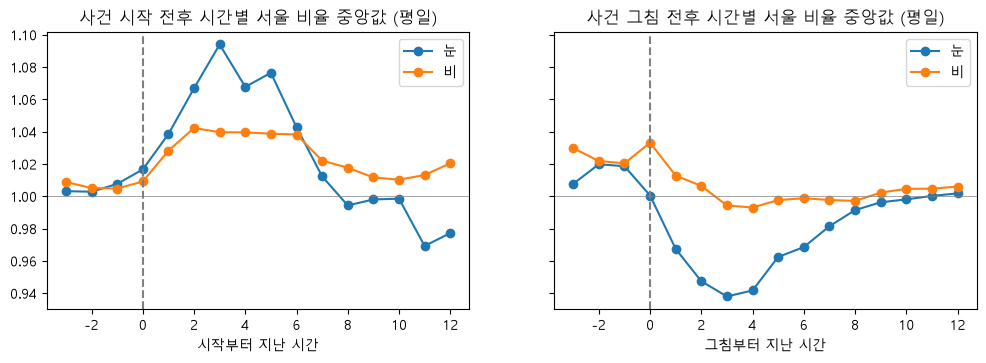

In [15]:
ev = load_processed('weather_events')
ev = ev[ev['intensity'].isin(['강한 비', '호우', '보통 눈', '많은 눈'])].copy()
ev['start'] = pd.to_datetime(ev['start']); ev['end'] = pd.to_datetime(ev['end'])
cs = city.assign(dt=city['date'] + pd.to_timedelta(city['hour'], unit='h')).set_index('dt')['ratio']
cs = cs[~cs.index.duplicated()]
wd_index = city[city['day2'].eq('평일')].assign(dt=lambda x: x['date'] + pd.to_timedelta(x['hour'], unit='h'))['dt']
wd_set = set(wd_index)
curves = []
for _, e in ev.iterrows():
    for ref, col in [('start', '시작'), ('end', '그침')]:
        for k in range(-3, 13):
            t = pd.Timestamp(e[ref]) + np.timedelta64(int(k), 'h')
            if t in wd_set and t in cs.index:
                curves.append({'kind': '눈' if e['type'] == 'snow' else '비', 'ref': col, 'k': k, 'ratio': cs[t]})
curves = pd.DataFrame(curves)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, ref in zip(axes, ['시작', '그침']):
    for kind, g in curves[curves['ref'].eq(ref)].groupby('kind'):
        m = g.groupby('k')['ratio'].median()
        ax.plot(m.index, m.values, marker='o', label=kind)
    ax.axvline(0, color='gray', ls='--'); ax.axhline(1, color='gray', lw=.5)
    ax.set_title(f'사건 {ref} 전후 시간별 서울 비율 중앙값 (평일)'); ax.set_xlabel(f'{ref}부터 지난 시간'); ax.legend()
fig.savefig(FIG / 'comparison_event_curve.png', dpi=150, bbox_inches='tight')
curves.groupby(['ref', 'kind', 'k'])['ratio'].median().unstack('k').round(3)

## 7. Q2 반복 취약 도로 (분석 설계 10.2) → C

계산은 `src/analysis/vulnerable_roads.py` (평일 출퇴근 · 정답용 평소값). 진행 순서는 7.3과 같다.
1. Train 사건으로 목록 후보를 만든다 (최소 비율 후보마다)
2. Dev 사건에서 목록이 상위 20%에 드는 비율(적중률)을 본다. 무작위면 20%라서 **lift = 적중률 ÷ 20%**. 목록이 5개 미만인 후보는 빼고 lift가 가장 큰 최소 비율을 고른다
3. 고른 최소 비율로 Train + Dev 전체 사건으로 다시 만든다 → **최종 목록** (`data/shared/train_dev/vulnerable_roads_train_dev.csv`)

In [16]:
if RUN_BUILD:
    subprocess.run([sys.executable, str(ROOT / 'src/analysis/vulnerable_roads.py')], check=True)
cand = pd.read_csv(TAB / 'vulnerable_min_ratio_dev.csv', encoding='utf-8-sig')
cand.round(3)

,type,min_ratio,n_list,train_events,dev_events,dev_hit_rate,lift,perm_p,chosen
0,snow,1.00,6,15,6,0.306,1.528,0.108,False
1,snow,1.02,6,15,6,0.306,1.528,0.103,False
2,snow,1.05,5,15,6,0.333,1.667,0.076,True
3,snow,1.08,4,15,6,0.375,1.875,0.047,False
4,snow,1.10,2,15,6,0.250,1.250,0.448,False
5,snow,1.15,0,15,6,NaN,NaN,NaN,False
6,snow,1.20,0,15,6,NaN,NaN,NaN,False
7,rain,1.00,11,22,14,0.597,2.987,0.000,False
8,rain,1.02,11,22,14,0.597,2.987,0.000,False
9,rain,1.05,11,22,14,0.597,2.987,0.000,False


In [17]:
final = pd.read_csv(ROOT / 'data/shared/train_dev/vulnerable_roads_train_dev.csv', encoding='utf-8-sig')
cols = ['type_name', 'road_name', 'direction', 'function_type', 'n_top20', 'type_events', 'hit_share', 'median_event_ratio', 'min_ratio']
final[final['is_vulnerable']][cols].round(3)

,type_name,road_name,direction,function_type,n_top20,type_events,hit_share,median_event_ratio,min_ratio
0,눈,동부간선도로,상행,도시고속도로,12,21,0.571,1.080,1.05
1,눈,분당수서로,상행,도시고속도로,11,21,0.524,1.097,1.05
2,눈,올림픽대로,상행,도시고속도로,11,21,0.524,1.083,1.05
3,눈,종암로,하행,주간선도로,11,21,0.524,1.050,1.05
180,비,경부고속도로,상행,도시고속도로,28,36,0.778,1.160,1.10
181,비,올림픽대로,상행,도시고속도로,26,36,0.722,1.137,1.10
182,비,분당수서로,하행,도시고속도로,24,36,0.667,1.133,1.10
183,비,강변북로,하행,도시고속도로,22,36,0.611,1.164,1.10
184,비,경부고속도로,하행,도시고속도로,22,36,0.611,1.108,1.10
185,비,올림픽대로,하행,도시고속도로,20,36,0.556,1.110,1.10


In [18]:
# 보조 확인 (7.3 (5)): 시즌 하나씩 빼고 나머지 시즌으로 목록을 만든 뒤, 뺀 시즌에서 확인 (최소 비율은 위에서 고른 값)
loso = pd.read_csv(TAB / 'vulnerable_leave_one_season_out.csv', encoding='utf-8-sig')
loso.round(3)

,type,held_out,build_events,held_out_events,n_list,hit_rate,lift,perm_p
0,snow,2022-23_winter,16,5,7,0.314,1.571,0.075
1,snow,2023-24_winter,11,10,5,0.300,1.500,0.117
2,snow,2024-25_winter,15,6,5,0.333,1.667,0.073
3,rain,2022-23_winter,34,2,8,0.562,2.812,0.003
4,rain,2023-24_winter,35,1,8,0.250,1.250,0.496
5,rain,2023_summer,26,10,12,0.542,2.708,0.000
6,rain,2024_summer,27,9,9,0.444,2.222,0.000
7,rain,2025_summer,22,14,6,0.655,3.274,0.000


맑은 날 대조: 사건마다 같은 시즌 · 요일 · 시각을 1~6주 옮겨 **모두 맑은 시간**으로 '가짜 사건'을 만들고, 같은 계산을 한다.
- `clear_lift`: 날씨 목록이 맑은 날에도 상위 20%에 드는 정도. 1이면 맑은 날엔 평범, 크면 날씨와 상관없이 원래 흔들리는 도로
- `n_vulnerable_if_clear`: 맑은 날로 같은 규칙(절반 이상 상위 20% + 최소 비율)을 돌렸을 때 뽑히는 도로 수

In [19]:
pd.read_csv(TAB / 'vulnerable_clear_control.csv', encoding='utf-8-sig').round(3)

,type,control_events,n_weather_list,clear_hit_rate,clear_lift,clear_perm_p,n_vulnerable_if_clear,overlap_with_weather_list
0,snow,21,4,0.226,1.131,0.341,0,0
1,rain,36,9,0.401,2.006,0.000,0,0


In [20]:
# 비 · 눈 목록이 겹치는 도로, 도로 유형 구성
v_only = final[final['is_vulnerable']]
print(v_only.groupby(['type_name', 'function_type']).size().unstack(fill_value=0))
both = (v_only.groupby(['road_name', 'direction'])['type_name'].apply(lambda s: ' · '.join(sorted(s)))
        .loc[lambda s: s.str.contains('·')])
print('눈 · 비 둘 다:', both.to_dict())

function_type  도시고속도로  주간선도로
type_name                   
눈                   3      1
비                   8      1
눈 · 비 둘 다: {('올림픽대로', '상행'): '눈 · 비'}


In [21]:
if OPEN_TEST:   # 마지막 평가 때 한 번만 (분석 설계 10.2 (3): lift 2배 이상 · 순열 p < 0.05 면 '반복된다')
    display(V.check_test(final))
else:
    print('Test 시즌은 아직 열지 않음 (OPEN_TEST = False)')

Test 시즌은 아직 열지 않음 (OPEN_TEST = False)


## 8. 정리 (Train + Dev, 평일 · 공휴일 제외)

**판정 표현**: 노션 6.3 (4)의 기준은 '학습 구간이 0 밖 + 학습 · 평가 시즌 방향이 같음'이다. 아래 '몰린다 · 덜하다'는 모두 **학습(Train + Dev) 기준을 충족했고 평가 확인 전**이라는 뜻이다. Train과 Dev를 따로 본 방향은 보조 확인으로만 적었다.

**Q3 출퇴근에 피해가 몰리나**
- **강한 비는 출퇴근에 몰린다.** 평일 출퇴근 서울 비율이 낮보다 +0.036, 밤보다 +0.052 높고, 95% 신뢰구간이 0을 포함하지 않는다 (Train · Dev를 따로 봐도 같은 방향) (맑음 대비 초과분: 출퇴근 +5.8% · 낮 +1.8% · 밤 +0.9%). 주말 출퇴근 시간대는 +3.6%로 평일보다 작다 → 날씨와 교통량이 겹칠 때 커진다.
- **호우 · 눈은 판정 보류.** 호우는 낮에 더 컸고(16개 사건), 눈은 사건이 적고(보통 눈 32 · 많은 눈 7개 묶음) Train과 Dev 방향이 엇갈린다. 2024-11-27 기록적 폭설 퇴근 시간처럼 **눈 영향 시간에 오히려 평소보다 빠른 시간**이 많아서다 (사건 그친 뒤 2~4시간 비율 0.94).
- 눈은 **내리는 동안**은 확실히 느리다: 시작 3시간 뒤 1.09, 3시간 신적설 1~3cm 1.09. 영향 시간(그친 뒤 12시간)에는 차가 줄어 빨라진 시간이 섞인다 (보완 1). 발동 기준(12/2)은 영향 시간 전체보다 '지금 내리는 눈 · 앞으로 3시간 예보'로 잡는 편이 맞다.
- **보완 1 (내리는 중 · 그친 뒤, 5-2)**: 강한 비는 **내리는 중**만 봐도 출퇴근에 몰린다 (낮보다 +0.028, 밤보다 +0.052, 둘 다 학습 기준 충족). 눈은 **그친 뒤 출퇴근이 오히려 더 빠르다** (낮보다 −0.104, 밤보다 −0.118, 둘 다 학습 기준 충족). 눈이 그친 다음 출퇴근길에 차를 두고 나오는 사람이 많다는 뜻으로 읽힌다 (교통량은 C 연관성 분석으로 확인). 눈이 **내리는 중**에는 출퇴근 중앙값 1.044 · 낮 1.004로 출퇴근이 더 느렸지만, 22개 사건뿐이라 구간이 0을 포함하고 Train과 Dev가 엇갈려 여전히 판정 보류다.
- **보완 2 (평일 − 주말, 5번)**: 강한 비 출퇴근은 평일이 주말보다 +0.025 더 느렸지만 구간이 0을 포함한다 (−0.007 ~ +0.053). '날씨 × 교통량이 겹칠 때 커진다'는 주말 비교만으로는 통계적으로 말할 수 없고, 방향만 맞다. 생존분석의 '곧 평일 출퇴근 · 주말' 위험비가 더 강한 근거다.
- **보완 3 (도로 유형별, 5-3)**: 예상과 달리 도시고속도로가 더 뚜렷하지 않았다. 도시고속도로는 22개 도로 · 방향뿐이라 시간마다 값이 크게 흔들려 구간이 넓다. 강한 비가 출퇴근에 몰리는 결과는 주간선도로에서 네 비교 모두 학습 기준을 충족했고, 도시고속도로는 네 중 두 개(밤과 비교)만 충족했다. 결론은 '도로 유형과 상관없이 강한 비는 출퇴근에 몰린다'로 둔다.
- **보조 확인 (로그 비율, 4-2)**: 도로마다 log(비율)의 평균(기하평균)으로 다시 판정해도 평일 Q3 판정 10개가 모두 같다 (강한 비 출퇴근 − 낮 +0.034 · − 밤 +0.046). 몇몇 크게 튄 도로 때문에 나온 결과가 아니다.
- 발표 문구: "24시간을 비교하니 **강한 비**는 같은 강도에서도 출퇴근에 지연이 가장 컸다 (도로 유형과 상관없이). 눈은 그친 뒤 출퇴근이 오히려 빨랐고, 내리는 동안의 시간대 차이는 사건이 적어 판정하지 못했다."

**Q1 얼마나 느려지나 (평일 출퇴근)**: 강한 비 도시고속도로 중앙값 1.05 · 상위 10% 1.47, 주간선도로 1.03 · 1.23. 시간당 강수가 많을수록 커진다 (1~5mm 1.09 → 10~30mm 1.12). 도시고속도로가 더 크게 느려진다.

**Q2 반복 취약 도로 (→ C)**
- **비는 반복된다**: Train 목록이 Dev 사건에서 상위 20%에 든 비율 65.5% (무작위 20%의 3.3배, 순열 p < 0.001). 최종 9개는 경부고속 · 올림픽대로 · 강변북로 양방향, 분당수서로 · 서부간선도로 · 동부간선도로 하행. 대부분 **하천변 도시고속도로**다.
- **시즌 하나씩 빼기**: 비는 사건이 많은 여름 3시즌 모두 뺀 시즌에서 lift 2.2~3.3배 (p < 0.001)로 반복됐다. 비 사건이 1~2개뿐인 겨울 시즌은 흔들린다. 눈은 세 겨울 모두 1.5~1.7배 (p 0.07~0.12)로 일관되게 약하다.
- **맑은 날 대조**: 비 목록 9개는 맑은 날 같은 시각에도 상위 20%에 2.0배로 자주 든다 (원래 출퇴근에 잘 흔들리는 도로). 비 오는 날은 3.3배라 비가 그 위에 더 얹힌다. 맑은 날로 같은 규칙을 돌리면 뽑히는 도로는 0개다 (최소 비율 1.10을 넘는 도로가 없음). 그래서 '비 오는 날 더 크게 무너지는 도로'라는 해석은 유지하되, 발표에서는 '평소에도 흔들리는 도로가 비에 더 무너진다'로 말한다. 눈 목록은 맑은 날 1.1배로 평범하다.
- **눈은 약하다**: Dev lift 1.67 (p 0.08)로 '2배 이상 · p < 0.05' 기준에 못 미친다. 최종 4개(동부간선 · 분당수서로 · 올림픽대로 상행, 종암로 하행)는 '후보'로 넘긴다.
- 간선도로는 비 1개(서부간선도로) · 눈 1개(종암로)뿐이라, C의 '취약 간선도로 × 열선'은 표본이 매우 작다.
- Test 확인(10.2 (3))은 아직 하지 않았다.

In [22]:
def fmt(r):
    return f"{r['학습 차이']:+.3f} [{r['95% 하한']:+.3f}, {r['95% 상한']:+.3f}] → {r['판정']}"
s = q3.set_index(['요일', '날씨', '비교'])
lines = []
for gname in ['비 전체', '눈 전체', '맑음']:
    for other in ['낮', '밤']:
        lines.append(f"평일 {gname} 출퇴근 − {other}: {fmt(s.loc[('평일', gname, f'출퇴근 − {other}')])}")
for kind in ['snow', 'rain']:
    c = cand[(cand['type'] == kind) & cand['chosen']].iloc[0]
    names = ', '.join(final[(final['type'] == kind) & final['is_vulnerable']]
                      .apply(lambda r: f"{r['road_name']}({r['direction']})", axis=1))
    lines.append(f"반복 취약 {V.KIND_NAME[kind]}: 최소 비율 {c['min_ratio']:.2f} · Dev lift {c['lift']:.2f} (순열 p {c['perm_p']:.3f}) · "
                 f"최종 {int(final[(final['type'] == kind)]['is_vulnerable'].sum())}개: {names}")
summary = '\n'.join(lines)
(TAB / 'ljh_comparison_summary.txt').write_text(summary, encoding='utf-8')
print(summary)

평일 비 전체 출퇴근 − 낮: +0.011 [-0.007, +0.038] → 판정 보류
평일 비 전체 출퇴근 − 밤: +0.033 [+0.015, +0.057] → 출퇴근에 몰림 (평가 확인 전)
평일 눈 전체 출퇴근 − 낮: +0.015 [-0.062, +0.055] → 판정 보류
평일 눈 전체 출퇴근 − 밤: -0.001 [-0.087, +0.034] → 판정 보류
평일 맑음 출퇴근 − 낮: -0.004 [-0.007, -0.000] → 출퇴근이 덜함 (평가 확인 전)
평일 맑음 출퇴근 − 밤: +0.003 [-0.001, +0.006] → 판정 보류
반복 취약 눈: 최소 비율 1.05 · Dev lift 1.67 (순열 p 0.076) · 최종 4개: 동부간선도로(상행), 분당수서로(상행), 올림픽대로(상행), 종암로(하행)
반복 취약 비: 최소 비율 1.10 · Dev lift 3.27 (순열 p 0.000) · 최종 9개: 경부고속도로(상행), 올림픽대로(상행), 분당수서로(하행), 강변북로(하행), 경부고속도로(하행), 올림픽대로(하행), 강변북로(상행), 서부간선도로(하행), 동부간선도로(하행)
